# 04 · Surrogate models

A **surrogate** (metamodel, response surface, emulator) is a cheap mathematical
function fitted to a limited number of runs of an expensive simulation. After
that, the surrogate is evaluated instead of the simulation – thousands of times
per second – for sweeps, sensitivity analysis and optimisation.

## 1 · When is a surrogate the right tool?

Count the runs the previous notebooks needed, and multiply by the run time of
*your* model:

| Task (8 parameters) | Runs | at 1 ms | at 5 s | at 10 min |
|---|---|---|---|---|
| One-at-a-time sweeps | ~300 | 0.3 s | 25 min | 2 days |
| Morris screening | ~300 | 0.3 s | 25 min | 2 days |
| Calibration, least squares | ~100 per start | 0.1 s | 8 min | 17 h |
| Calibration, scalar optimiser | 400–2000 | 2 s | 3 h | 2 weeks |
| Sobol indices | 5 000–20 000 | 20 s | 1 day | 5 months |
| Global optimisation / Pareto front | 5 000–15 000 | 15 s | 20 h | 3 months |
| Robust optimisation (× Monte Carlo) | 10⁴–10⁵ | 1.5 min | 6 days | – |

**Use a surrogate when** the run count of what you want to do, times the run
time, is more than you can afford – *and* the following hold:

* the outputs you need are a **few scalars** (KPIs) or a low-dimensional curve,
* they depend **smoothly** on the inputs (no jumps, no solver failures in the region),
* the number of inputs is **moderate** (up to ~10–20 for the methods here),
* you will reuse the surrogate for many evaluations (several studies, an
  optimisation, real-time use).

**Don't** when the model is already fast (notebooks 01–03: no surrogate
needed, and none used), when a least-squares calibration converges in a hundred
runs anyway, or when you only need a handful of what-if runs. A surrogate adds
its own error and its own validation work; it has to earn that.

## 2 · An expensive model: the nonlinear clutch damper in the time domain

Real clutch dampers are not linear springs. `dl.nl_simulate` models a two-stage
characteristic (soft pre-stage up to the angle `phi1`, then main-stage stiffness
`k2`) with a friction hysteresis `T_hyst`. That cannot be solved order by order
in the frequency domain – the response depends on the amplitude and on the mean
torque – so each speed point is a time integration until steady state. It plays
the role of your Dymola or multibody model.

In [1]:
import os
import time
import warnings
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import driveline as dl
import plotstyle
C = plotstyle.use()
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", module="sklearn")
np.set_printoptions(precision=3, suppress=True)

D = len(dl.NL_NAMES)
print(f"{'design variable':16s} {'baseline':>9s} {'lower':>8s} {'upper':>8s}  unit")
for r in dl.NL_TABLE:
    print(f"{r[0]:16s} {r[1]:9.4g} {r[2]:8.4g} {r[3]:8.4g}  {r[4]}")

design variable   baseline    lower    upper  unit
k2                    1600      800     3200  Nm/rad
phi1                  0.03    0.005     0.08  rad
T_hyst                   3      0.5       12  Nm
J_add                    0        0    0.004  kgm2


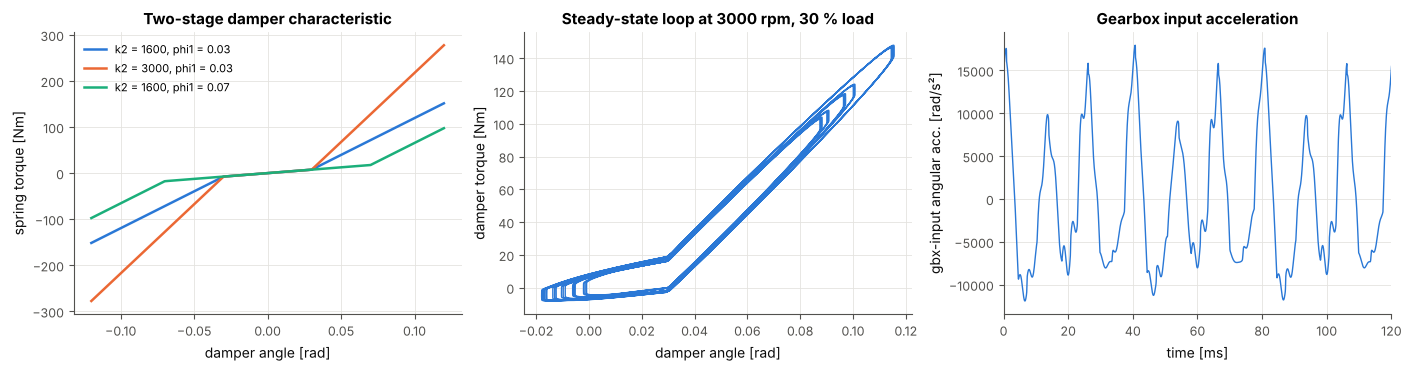

one speed point: 0.18 s;  one run-up (17 speeds): 3.9 s
baseline design: rattle index = 5439 rad/s²,  max wind-up = 0.116 rad


In [2]:
k1 = 250.0
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
d = np.linspace(-0.12, 0.12, 400)
for k2, phi1, c in ((1600, 0.03, C[0]), (3000, 0.03, C[1]), (1600, 0.07, C[2])):
    f = np.where(np.abs(d) < phi1, k1 * d, np.sign(d) * (k1 * phi1 + k2 * (np.abs(d) - phi1)))
    ax[0].plot(d, f, color=c, label=f"k2 = {k2}, phi1 = {phi1}")
ax[0].set(xlabel="damper angle [rad]", ylabel="spring torque [Nm]", title="Two-stage damper characteristic")
ax[0].legend(fontsize=8)

t0 = time.perf_counter()
pt = dl.nl_point(dl.NL_NOMINAL, 3000.0, load=0.3, return_series=True)
t_point = time.perf_counter() - t0
ax[1].plot(pt["d"], pt["t_damper"], lw=1)
ax[1].set(xlabel="damper angle [rad]", ylabel="damper torque [Nm]",
          title="Steady-state loop at 3000 rpm, 30 % load")
tt = np.arange(len(pt["acc"])) * pt["dt"] * 1e3
ax[2].plot(tt, pt["acc"], lw=1)
ax[2].set(xlabel="time [ms]", ylabel="gbx-input angular acc. [rad/s²]", xlim=(0, 120),
          title="Gearbox input acceleration")
plt.show()

t0 = time.perf_counter()
base = dl.nl_kpi(dl.NL_NOMINAL)
t_run = time.perf_counter() - t0
print(f"one speed point: {t_point:.2f} s;  one run-up ({len(dl.NL_RPM)} speeds): {t_run:.1f} s")
print(f"baseline design: rattle index = {base[0]:.0f} rad/s²,  max wind-up = {base[1]:.3f} rad")

The loop in the middle shows the nonlinearity: the kink where the pre-stage
ends, and the width caused by friction. One run-up takes a few seconds – about
5000 times slower than the linear model. A 10 000-run study would take most of
a day here, and your real models are slower still.

From each run-up we keep two numbers (`dl.nl_kpi`):

* **rattle index** – mean rms angular acceleration of the gearbox input shaft
  over 2000–6000 rpm at 30 % load (to be minimised),
* **wind-up** – largest damper angle (must stay below the travel limit).

The surrogate workflow is always the same five steps:

1. choose inputs, ranges and outputs,
2. run a space-filling **design of experiments** (DoE) on the expensive model,
3. fit one or more surrogate types,
4. **validate** on runs the surrogate has not seen,
5. use it – and verify important conclusions with a few real runs.

## 3 · Design of experiments

128 Sobol points for training (nested: the first 16, 32, 64 are themselves good
designs, so we can study how the error falls with the number of runs), plus 48
independent Latin-hypercube points for testing. Results are cached on disk – the
single most useful habit when runs are expensive. The cache files ship with the
notebook; delete them to recompute (about 5–10 minutes).

training outputs, min … max: [2614.957    0.058] … [8059.302    0.225]


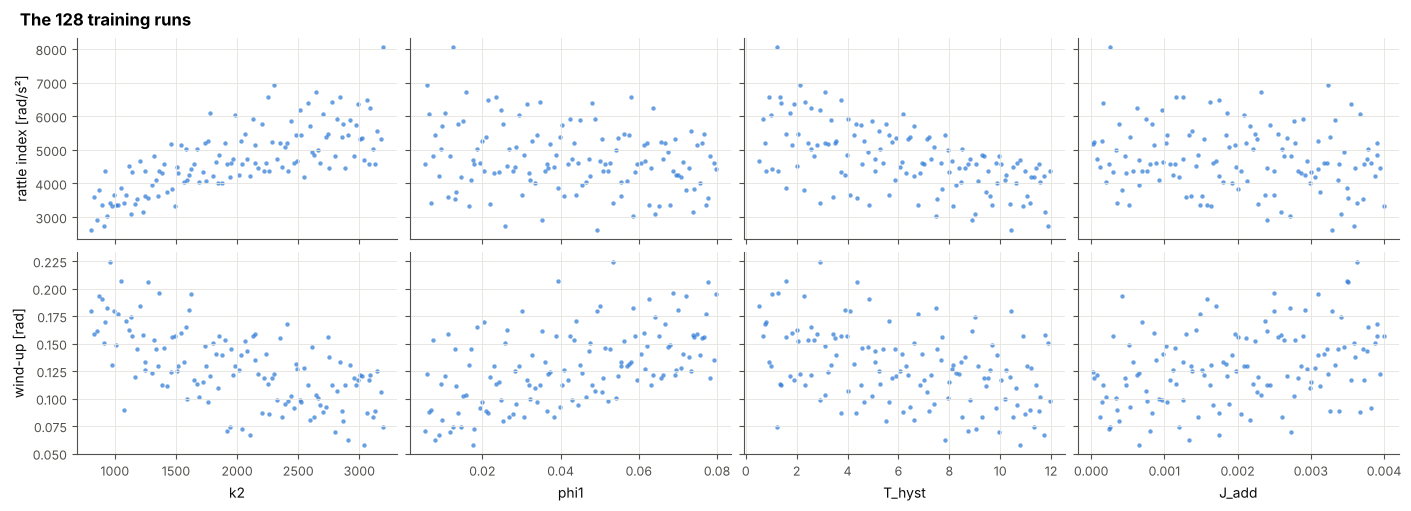

In [3]:
def to_design(U):
    return dl.NL_LOWER + np.atleast_2d(U) * (dl.NL_UPPER - dl.NL_LOWER)


def run_expensive(U, cache=None, workers=2):
    """Evaluate dl.nl_kpi for all rows of U (unit cube), in parallel, with a disk cache."""
    if cache and os.path.exists(cache):
        z = np.load(cache)
        if z["U"].shape == U.shape and np.allclose(z["U"], U):
            return z["Y"]
    t0 = time.perf_counter()
    with ProcessPoolExecutor(workers) as ex:
        Y = np.array(list(ex.map(dl.nl_kpi, to_design(U))))
    print(f"ran {len(U)} expensive simulations in {time.perf_counter() - t0:.0f} s")
    if cache:
        np.savez(cache, U=U, Y=Y)
    return Y


U_train = qmc.Sobol(d=D, seed=11).random(128)
U_test = qmc.LatinHypercube(d=D, seed=12).random(48)
Y_train = run_expensive(U_train, "data/nl_doe_train.npz")
Y_test = run_expensive(U_test, "data/nl_doe_test.npz")
OUT = ["rattle index [rad/s²]", "wind-up [rad]"]
print("training outputs, min … max:", Y_train.min(0).round(3), "…", Y_train.max(0).round(3))

fig, axes = plt.subplots(2, D, figsize=(14, 5), sharex="col", sharey="row")
for k in range(2):
    for j in range(D):
        axes[k, j].scatter(to_design(U_train)[:, j], Y_train[:, k], s=10, alpha=0.7, linewidths=0)
        if k == 1:
            axes[k, j].set_xlabel(dl.NL_NAMES[j])
    axes[k, 0].set_ylabel(OUT[k])
fig.suptitle("The 128 training runs", x=0.01, ha="left", fontweight="bold")
plt.show()

Always plot the raw DoE results first. Trends are already visible (stiffer
`k2` → more rattle, less wind-up), and you would spot failed runs or outliers
here before they poison a surrogate.

## 4 · Three surrogate types

**Quadratic response surface.** $\hat y = \beta_0 + \sum\beta_i u_i + \sum\beta_{ij}u_iu_j$.
For 4 inputs that is 15 coefficients, fitted by linear least squares. Simple,
transparent, needs few runs, cannot follow anything more complicated than a bowl
or a saddle.

**Gaussian process (kriging).** Think of it as interpolation with a
principled error bar. The assumption: outputs at nearby inputs are correlated,
with a correlation that decays with distance according to a *kernel*

$$k(\mathbf{u},\mathbf{u}') = \sigma_f^2\; \text{Matérn}_{5/2}\!\Big(\sqrt{\textstyle\sum_j (u_j-u'_j)^2/\ell_j^2}\Big) + \sigma_n^2\,\delta_{\mathbf{u}\mathbf{u}'}$$

The **length scales** $\ell_j$ (one per input – "ARD") say how quickly the
output changes along each input; they are learned from the data by maximising
the likelihood. A long length scale means "this input hardly matters" – a
built-in sensitivity measure. The **nugget** $\sigma_n^2$ absorbs numerical noise of the
simulation, so the GP need not pass exactly through every point. The prediction
at a new point is a weighted average of the training outputs *plus a standard
deviation* that grows with distance from the data. That uncertainty is what
makes GPs the default surrogate for small, expensive data sets (tens to a few
thousand runs; training cost grows with N³).

**Neural network (small MLP).** A flexible function built from layers of
weighted sums and nonlinearities. No built-in uncertainty, many more settings,
hungry for data – but it scales to large data sets and many outputs, where GPs
stop being practical. Notebook 06 returns to this.

In all cases: inputs scaled to the unit cube, outputs standardised.

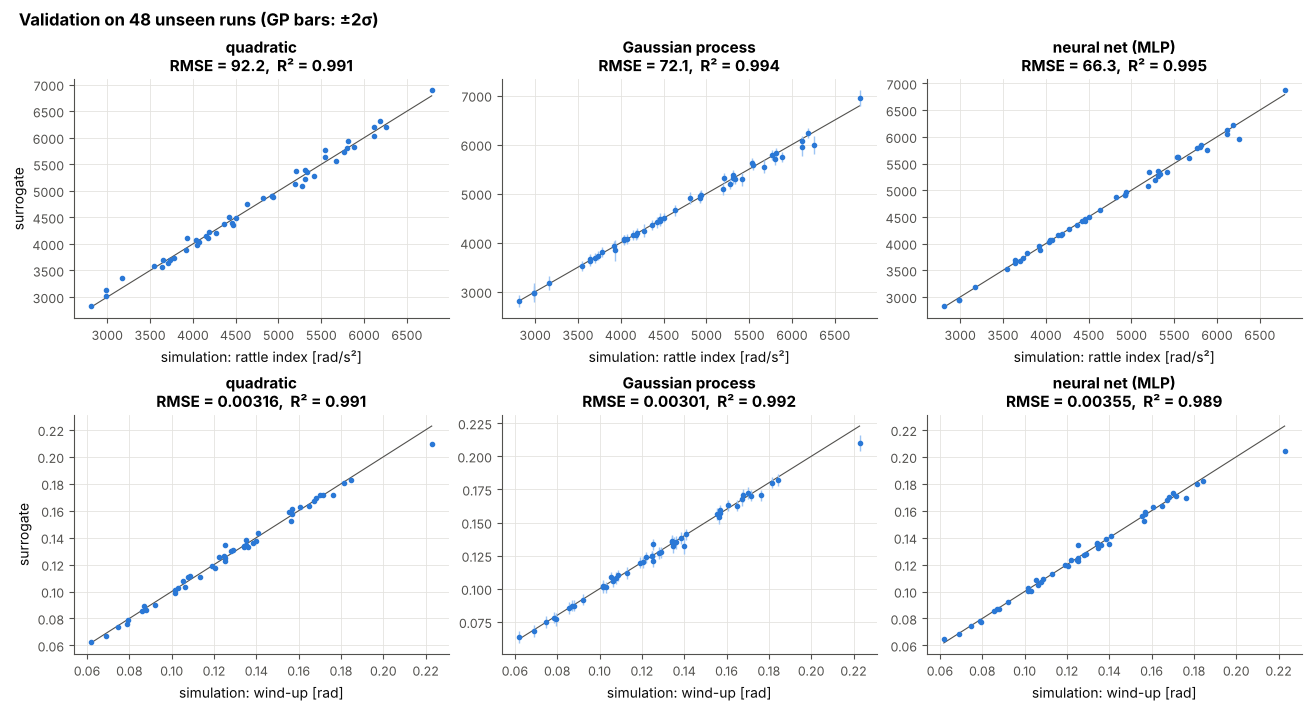

In [4]:
def fit_gp(U, y, restarts=4):
    kernel = (ConstantKernel(1.0, (1e-2, 1e3))
              * Matern(length_scale=np.ones(U.shape[1]), length_scale_bounds=(0.05, 20.0), nu=2.5)
              + WhiteKernel(1e-3, (1e-6, 1e-1)))
    return GaussianProcessRegressor(kernel, normalize_y=True, n_restarts_optimizer=restarts,
                                    random_state=0).fit(U, y)


def fit_quadratic(U, y):
    return make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(U, y)


class ScaledMLP:
    """sklearn MLP with standardised output (lbfgs solver suits small data sets)."""
    def fit(self, U, y):
        self.sc = StandardScaler().fit(y[:, None])
        self.net = MLPRegressor(hidden_layer_sizes=(32, 32), activation="tanh", solver="lbfgs",
                                alpha=1e-2, max_iter=5000, random_state=0)
        self.net.fit(U, self.sc.transform(y[:, None]).ravel())
        return self

    def predict(self, U):
        return self.sc.inverse_transform(self.net.predict(U)[:, None]).ravel()


FITTERS = {"quadratic": fit_quadratic, "Gaussian process": fit_gp, "neural net (MLP)": lambda U, y: ScaledMLP().fit(U, y)}
models = {name: [f(U_train, Y_train[:, k]) for k in range(2)] for name, f in FITTERS.items()}

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for k in range(2):
    for a, (name, m) in zip(axes[k], models.items()):
        pred = m[k].predict(U_test)
        err = pred - Y_test[:, k]
        r2 = 1 - np.sum(err ** 2) / np.sum((Y_test[:, k] - Y_test[:, k].mean()) ** 2)
        lim = [Y_test[:, k].min(), Y_test[:, k].max()]
        a.plot(lim, lim, color=plotstyle.MUTED, lw=0.8)
        if name == "Gaussian process":
            _, sd = m[k].predict(U_test, return_std=True)
            a.errorbar(Y_test[:, k], pred, yerr=2 * sd, fmt="o", ms=3, color=C[0], ecolor="#9ec5f4", elinewidth=1)
        else:
            a.plot(Y_test[:, k], pred, "o", ms=3, color=C[0])
        a.set(title=f"{name}\nRMSE = {np.sqrt(np.mean(err ** 2)):.3g},  R² = {r2:.3f}",
              xlabel=f"simulation: {OUT[k]}", ylabel="surrogate" if a is axes[k, 0] else "")
fig.suptitle("Validation on 48 unseen runs (GP bars: ±2σ)", x=0.01, ha="left", fontweight="bold")
plt.show()

**Predicted-versus-actual on held-out runs is the one plot a surrogate must
pass.** Never judge a surrogate by how well it reproduces its training points –
a GP reproduces them almost perfectly by construction.

Here all three do well and are close to each other. That is a result, not
a disappointment: the two KPIs are smooth, nearly quadratic functions of the four
inputs over these ranges, so the simplest model is already adequate. A flexible
model only pays off when the response has more structure than a bowl. Start
simple, and let the validation error tell you whether you need more.

How many runs were needed?

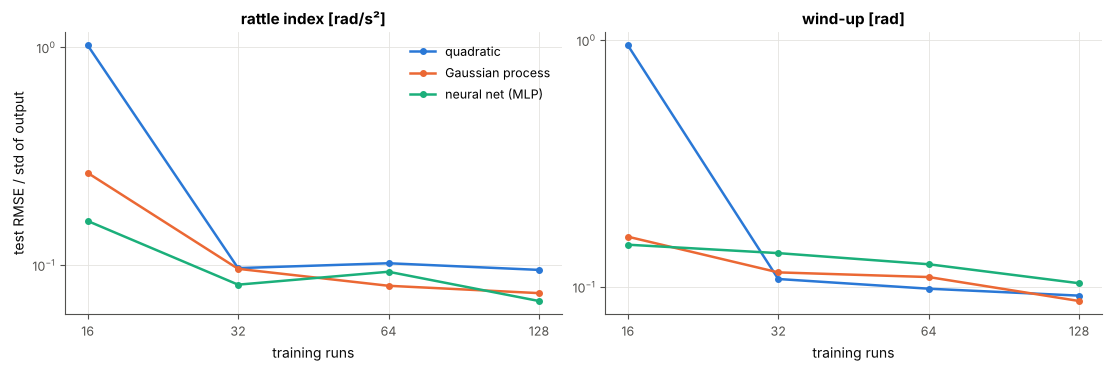

In [5]:
sizes = [16, 32, 64, 128]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for k, a in enumerate(axes):
    for (name, f), c in zip(FITTERS.items(), C):
        rm = [np.sqrt(np.mean((f(U_train[:n], Y_train[:n, k]).predict(U_test) - Y_test[:, k]) ** 2)) for n in sizes]
        a.plot(sizes, np.array(rm) / Y_test[:, k].std(), "o-", color=c, label=name)
    a.set(xscale="log", yscale="log", xticks=sizes, xticklabels=sizes, xlabel="training runs",
          title=OUT[k], ylabel="test RMSE / std of output" if k == 0 else "")
    a.minorticks_off()
axes[0].legend()
plt.show()

* With 16 runs the quadratic surface is useless – it has 15 coefficients, so
  there is nothing left to average out noise. GP and MLP degrade more gracefully.
  A common rule of thumb for a first DoE is **about 10 runs per input**.
* From 32 runs on, all three reach an error of roughly 10 % of the output's
  spread and then **stop improving**. More runs do not help because the remaining
  error is not the surrogate's: the KPI itself carries numerical "noise" (17
  discrete speed points, finite settling time). The GP's nugget term estimates
  that noise level. Knowing the noise floor of your simulation tells you when
  to stop adding runs.

### 4.1 Is the GP's error bar honest?

A GP claims to know its own uncertainty. Check it: the standardised errors
(actual − predicted)/σ on the test set should look like a standard normal
distribution – about 95 % within ±2.

rattle index [rad/s²]    length scales (unit cube): k2 2.0, phi1 2.3, T_hyst 3.1, J_add 4.6
wind-up [rad]            length scales (unit cube): k2 3.2, phi1 14.2, T_hyst 4.6, J_add 9.0


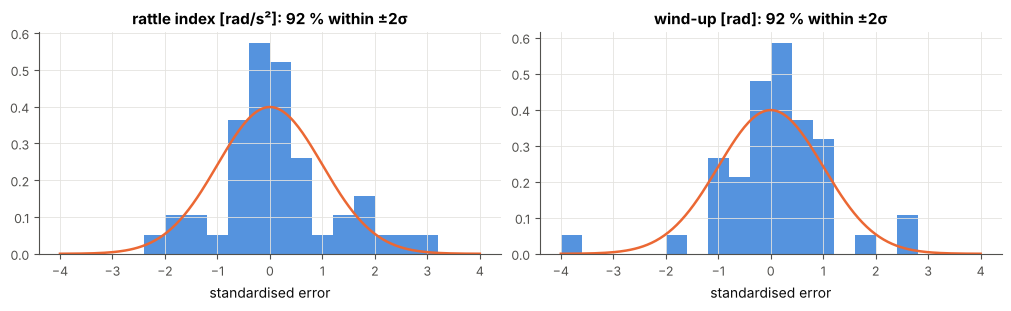

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for k, a in enumerate(axes):
    mu, sd = models["Gaussian process"][k].predict(U_test, return_std=True)
    z = (Y_test[:, k] - mu) / sd
    a.hist(z, bins=np.linspace(-4, 4, 21), density=True, color=C[0], alpha=0.8)
    zz = np.linspace(-4, 4, 200)
    a.plot(zz, norm.pdf(zz), color=C[1])
    a.set(title=f"{OUT[k]}: {100 * np.mean(np.abs(z) < 2):.0f} % within ±2σ", xlabel="standardised error")
    ls = models["Gaussian process"][k].kernel_.k1.k2.length_scale
    print(f"{OUT[k]:24s} length scales (unit cube): " + ", ".join(f"{n} {v:.1f}" for n, v in zip(dl.NL_NAMES, ls)))
plt.show()

The error bars are slightly optimistic here (a little over 90 % instead of 95 %
inside ±2σ) but usable. The length scales are a free by-product: the shorter, the more the output reacts
to that input within the range (a value of 20 is the upper limit of the search
and means "practically flat").

## 5 · Using the surrogate

### 5.1 Sobol indices for free

Notebook 02 needed some 20 000 runs for converged Sobol indices – more than a
day with this model. On the surrogate it is a fraction of a second.

49152 surrogate evaluations in 0.1 s  (real model: about 54 h)


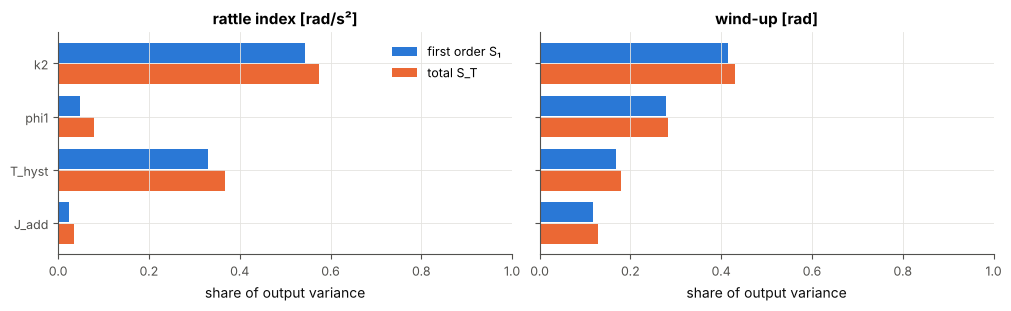

In [7]:
def sobol_indices(f, d, n, seed=0):
    """Vectorised Saltelli/Jansen estimators; f maps (m, d) arrays to (m,) arrays."""
    AB = qmc.Sobol(d=2 * d, seed=seed).random(n)
    A, B = AB[:, :d], AB[:, d:]
    fA, fB = f(A), f(B)
    var = np.var(np.concatenate([fA, fB]))
    S1, ST = np.empty(d), np.empty(d)
    for i in range(d):
        ABi = A.copy(); ABi[:, i] = B[:, i]
        fABi = f(ABi)
        S1[i] = np.mean(fB * (fABi - fA)) / var
        ST[i] = 0.5 * np.mean((fA - fABi) ** 2) / var
    return S1, ST


gp_rattle, gp_windup = models["Gaussian process"]
t0 = time.perf_counter()
sob = [sobol_indices(m.predict, D, 4096) for m in (gp_rattle, gp_windup)]
n_eval = 2 * 4096 * (D + 2)
print(f"{n_eval} surrogate evaluations in {time.perf_counter() - t0:.1f} s  "
      f"(real model: about {n_eval * t_run / 3600:.0f} h)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
y = np.arange(D)[::-1]
for a, (S1, ST), name in zip(axes, sob, OUT):
    a.barh(y + 0.2, S1, 0.38, label="first order S₁")
    a.barh(y - 0.2, ST, 0.38, label="total S_T")
    a.set(title=name, xlabel="share of output variance", xlim=(0, 1))
axes[0].set_yticks(y, dl.NL_NAMES)
axes[0].legend()
plt.show()

### 5.2 Maps of the design space

Two-dimensional cuts through the surrogate, with the wind-up limit drawn in.
Suppose the travel limit of the damper is **0.10 rad**. The baseline design
(wind-up 0.116 rad) does not meet it, so a redesign is needed anyway.

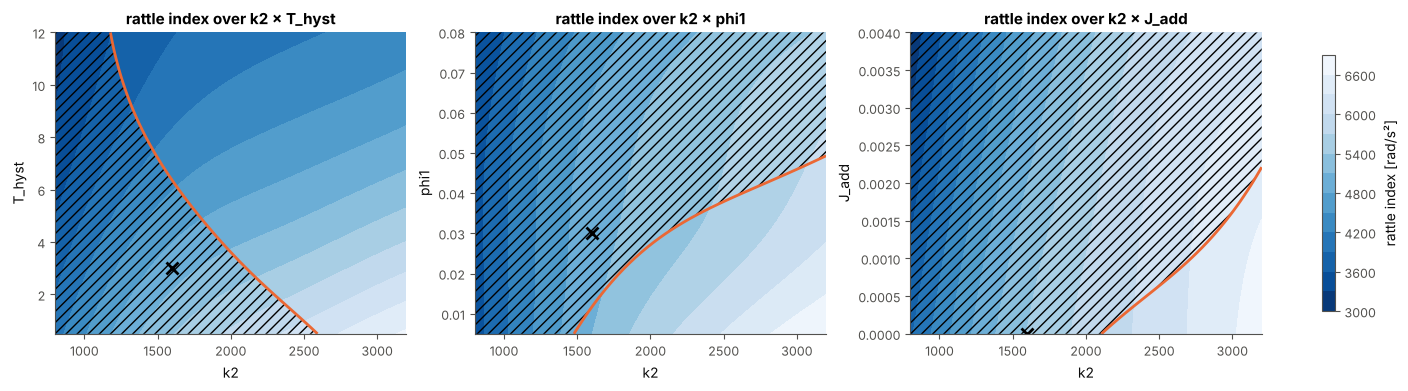

In [8]:
WINDUP_MAX = 0.10
u_base = (dl.NL_NOMINAL - dl.NL_LOWER) / (dl.NL_UPPER - dl.NL_LOWER)


def slice_map(ax, ia, ib, u_ref, n=60):
    ga, gb = np.linspace(0, 1, n), np.linspace(0, 1, n)
    G = np.tile(u_ref, (n * n, 1))
    G[:, ia], G[:, ib] = np.repeat(ga, n), np.tile(gb, n)
    r = gp_rattle.predict(G).reshape(n, n).T
    w = gp_windup.predict(G).reshape(n, n).T
    xa = dl.NL_LOWER[ia] + ga * (dl.NL_UPPER[ia] - dl.NL_LOWER[ia])
    xb = dl.NL_LOWER[ib] + gb * (dl.NL_UPPER[ib] - dl.NL_LOWER[ib])
    cs = ax.contourf(xa, xb, r, levels=12, cmap="Blues_r")
    ax.contourf(xa, xb, w, levels=[WINDUP_MAX, 10], colors="none", hatches=["///"])
    ax.contour(xa, xb, w, levels=[WINDUP_MAX], colors=[C[1]], linewidths=2)
    ax.plot(dl.NL_NOMINAL[ia], dl.NL_NOMINAL[ib], "x", color="k", ms=8, mew=2)
    ax.set(xlabel=dl.NL_NAMES[ia], ylabel=dl.NL_NAMES[ib])
    ax.grid(False)
    return cs


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (ia, ib) in zip(axes, ((0, 2), (0, 1), (0, 3))):
    cs = slice_map(a, ia, ib, u_base)
    a.set_title(f"rattle index over {dl.NL_NAMES[ia]} × {dl.NL_NAMES[ib]}")
fig.colorbar(cs, ax=axes, label="rattle index [rad/s²]", shrink=0.85)
plt.show()

Dark = low rattle; hatched = wind-up above the limit (orange line); cross =
baseline, other inputs held at baseline. The conflict is plain: rattle wants a
soft main stage, the travel limit forbids it, and more friction relaxes both.

### 5.3 Optimising on the surrogate – and checking with the real model

The direct approach: minimise the GP's rattle prediction subject to the GP's
wind-up prediction ≤ limit, then **run the real model at the proposed point**.

In [9]:
cand = qmc.Sobol(d=D, seed=99).random(2 ** 15)          # dense candidate set; cheap on a surrogate


def surrogate_optimum(g_r, g_w):
    r, w = g_r.predict(cand), g_w.predict(cand)
    i = np.argmin(np.where(w <= WINDUP_MAX, r, np.inf))
    return cand[i], r[i], w[i]


u_s, r_pred, w_pred = surrogate_optimum(gp_rattle, gp_windup)
y_s = dl.nl_kpi(to_design(u_s)[0])
print("proposed design:", {n: round(float(v), 4) for n, v in zip(dl.NL_NAMES, to_design(u_s)[0])})
print(f"  surrogate predicts  rattle {r_pred:.0f}, wind-up {w_pred:.4f}")
print(f"  real model gives    rattle {y_s[0]:.0f}, wind-up {y_s[1]:.4f}"
      f"   → {'feasible' if y_s[1] <= WINDUP_MAX else 'VIOLATES the limit'}")

proposed design: {'k2': 928.9108, 'phi1': 0.008, 'T_hyst': 11.3415, 'J_add': 0.0004}
  surrogate predicts  rattle 3200, wind-up 0.0996
  real model gives    rattle 3216, wind-up 0.1006   → VIOLATES the limit


The rattle prediction is good, but look at the constraint: the optimiser
drives the design exactly onto the predicted limit, so the surrogate's small
error decides whether the real design is feasible – it is a coin toss. This is
generic: **optimisation seeks out the places where the surrogate is wrong in
your favour.** A one-shot "fit, optimise, done" is not safe.

### 5.4 Adaptive sampling (Bayesian optimisation)

The remedy is a loop: propose a point, run the real model there, add the result
to the training set, refit, repeat. New runs then go exactly where they matter –
near the optimum and along the constraint boundary – instead of being spread
uniformly. The proposal uses the GP's uncertainty through an **acquisition
function**. The classic one is *expected improvement* (EI):

$$\mathrm{EI}(\mathbf{u}) = (y_{\text{best}}-\mu)\,\Phi(z) + \sigma\,\varphi(z),\qquad z=\frac{y_{\text{best}}-\mu}{\sigma}$$

It is large where the predicted mean $\mu$ is low (exploitation) *or* the
uncertainty $\sigma$ is high (exploration). For the constraint we multiply by the
probability that the wind-up GP predicts a feasible design.

To show how little data this needs we start from only the first 32 DoE runs.

In [10]:
def expected_feasible_improvement(g_r, g_w, y_best):
    mu, sd = g_r.predict(cand, return_std=True)
    mw, sw = g_w.predict(cand, return_std=True)
    z = (y_best - mu) / sd
    ei = (y_best - mu) * norm.cdf(z) + sd * norm.pdf(z)
    return ei * norm.cdf((WINDUP_MAX - mw) / sw)


U_a, Y_a = U_train[:32].copy(), Y_train[:32].copy()
used, log = [], []
t0 = time.perf_counter()
for it in range(10):
    g_r, g_w = fit_gp(U_a, Y_a[:, 0], restarts=2), fit_gp(U_a, Y_a[:, 1], restarts=2)
    feas = Y_a[:, 1] <= WINDUP_MAX
    y_best = Y_a[feas, 0].min()
    acq = expected_feasible_improvement(g_r, g_w, y_best)
    acq[used] = -1.0
    i = int(np.argmax(acq)); used.append(i)
    y_new = dl.nl_kpi(to_design(cand[i])[0])                  # one expensive run
    U_a, Y_a = np.vstack([U_a, cand[i]]), np.vstack([Y_a, y_new])
    log.append((len(U_a), y_new[0], y_new[1], min(y_best, y_new[0]) if y_new[1] <= WINDUP_MAX else y_best))
    print(f"run {len(U_a):3d}: rattle {y_new[0]:5.0f}, wind-up {y_new[1]:.4f} "
          f"{'feasible  ' if y_new[1] <= WINDUP_MAX else 'infeasible'}  best feasible so far {log[-1][3]:.0f}")
print(f"{time.perf_counter() - t0:.0f} s")

feas = Y_a[:, 1] <= WINDUP_MAX
j = np.argmin(np.where(feas, Y_a[:, 0], np.inf))
d_best = to_design(U_a[j])[0]

run  33: rattle  3489, wind-up 0.0838 feasible    best feasible so far 3489


run  34: rattle  3345, wind-up 0.0925 feasible    best feasible so far 3345


run  35: rattle  3216, wind-up 0.1006 infeasible  best feasible so far 3345


run  36: rattle  3243, wind-up 0.0984 feasible    best feasible so far 3243


run  37: rattle  3136, wind-up 0.1036 infeasible  best feasible so far 3243


run  38: rattle  3205, wind-up 0.1035 infeasible  best feasible so far 3243


run  39: rattle  3147, wind-up 0.1056 infeasible  best feasible so far 3243


run  40: rattle  3162, wind-up 0.1043 infeasible  best feasible so far 3243


run  41: rattle  3217, wind-up 0.1042 infeasible  best feasible so far 3243


run  42: rattle  3172, wind-up 0.1068 infeasible  best feasible so far 3243
43 s


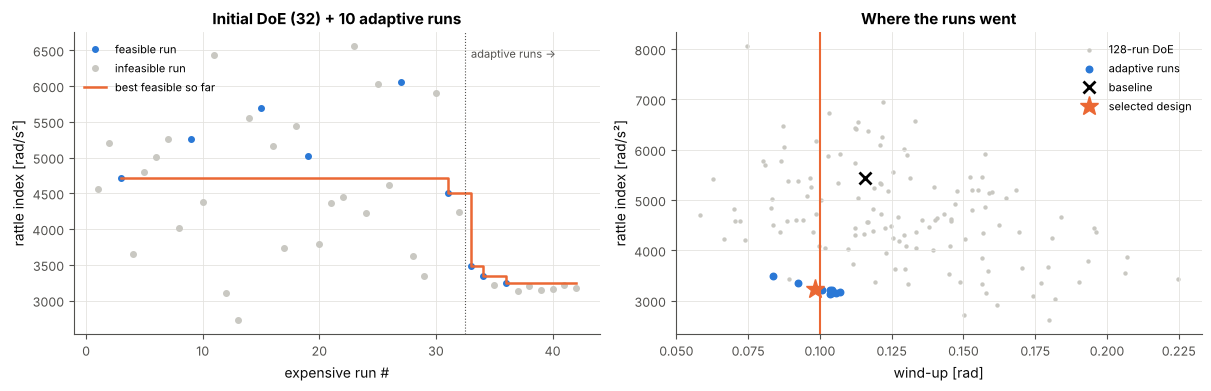

selected design: {'k2': 903.8815, 'phi1': 0.0052, 'T_hyst': 10.6852, 'J_add': 0.0002}
  rattle 3243 (baseline 5439, -40 %),  wind-up 0.0984 (baseline 0.116, limit 0.1)
  best feasible design in the full 128-run DoE: rattle 3426


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
n_all = np.arange(1, len(Y_a) + 1)
best_trace = [np.min(np.where(Y_a[:n, 1] <= WINDUP_MAX, Y_a[:n, 0], np.inf)) for n in n_all]
ax[0].plot(n_all[Y_a[:, 1] <= WINDUP_MAX], Y_a[Y_a[:, 1] <= WINDUP_MAX, 0], "o", color=C[0], label="feasible run")
ax[0].plot(n_all[Y_a[:, 1] > WINDUP_MAX], Y_a[Y_a[:, 1] > WINDUP_MAX, 0], "o", color="#c9c8c2", label="infeasible run")
ax[0].step(n_all, best_trace, where="post", color=C[1], label="best feasible so far")
ax[0].axvline(32.5, color=plotstyle.MUTED, lw=0.8, ls=":")
ax[0].text(33, ax[0].get_ylim()[1] * 0.97, "adaptive runs →", fontsize=8, color=plotstyle.MUTED, va="top")
ax[0].set(xlabel="expensive run #", ylabel="rattle index [rad/s²]", title="Initial DoE (32) + 10 adaptive runs")
ax[0].legend(loc="upper left", fontsize=8)

ax[1].scatter(Y_train[:, 1], Y_train[:, 0], s=10, color="#c9c8c2", linewidths=0, label="128-run DoE")
ax[1].scatter(Y_a[32:, 1], Y_a[32:, 0], s=22, color=C[0], label="adaptive runs")
ax[1].plot(base[1], base[0], "x", color="k", ms=8, mew=2, label="baseline")
ax[1].plot(Y_a[j, 1], Y_a[j, 0], "*", color=C[1], ms=14, label="selected design")
ax[1].axvline(WINDUP_MAX, color=C[1], lw=1.5)
ax[1].set(xlabel="wind-up [rad]", ylabel="rattle index [rad/s²]", title="Where the runs went")
ax[1].legend(fontsize=8)
plt.show()

print("selected design:", {n: round(float(v), 4) for n, v in zip(dl.NL_NAMES, d_best)})
print(f"  rattle {Y_a[j, 0]:.0f} (baseline {base[0]:.0f}, {100 * (Y_a[j, 0] / base[0] - 1):+.0f} %),  "
      f"wind-up {Y_a[j, 1]:.4f} (baseline {base[1]:.3f}, limit {WINDUP_MAX})")
print(f"  best feasible design in the full 128-run DoE: rattle {Y_train[Y_train[:, 1] <= WINDUP_MAX, 0].min():.0f}")

With 32 + 10 = 42 expensive runs the loop finds a design that is verified by
the real model, meets the travel limit and has a far lower rattle index than
the baseline – better than the best of 128 space-filling runs. The right-hand
plot shows why: the adaptive runs cluster at the lower-left corner of the
feasible region, right at the limit. After the first four adaptive runs the
best value no longer moves: the loop keeps probing the constraint boundary and
most of the later runs land just outside it. That is the signal to stop – and a
hint that this simple acquisition is a little too optimistic about feasibility
(exercise 2).

In practice use a maintained library for this loop –
[BoTorch](https://botorch.org)/[Ax](https://ax.dev) or `scikit-optimize` – which
also offer batch proposals (several runs in parallel), noisy and multi-objective
variants. The mechanics are what you see above.

## 6 · Pitfalls

* **Extrapolation.** A surrogate knows nothing outside its DoE box. Keep the
  box as part of the surrogate (clip or refuse inputs outside it).
* **Dimension.** Space-filling needs runs that grow quickly with the number of
  inputs. Screen first (Morris, notebook 02) and build the surrogate over the
  5–10 inputs that matter.
* **Non-smooth outputs.** Jumps (contact opening, a mode appearing, a solver
  switching branches) and `argmax`-type KPIs (remember "rpm of the peak" in
  notebook 02) defeat smooth surrogates. Redefine the KPI or split the domain.
* **Failed runs.** Record them; a region where the simulation crashes needs a
  feasibility model, not a fake value.
* **Curves instead of scalars.** If you need a whole run-up curve, a surrogate
  per point does not scale. Compress the curve (principal components) and model
  the few coefficients – notebook 06.
* **Validation is not optional.** Hold-out runs for the surrogate, real runs for
  every conclusion that matters.

## 7 · Summary

| | Quadratic RSM | Gaussian process | Neural network |
|---|---|---|---|
| Runs needed | ≥ 2× number of coefficients | ~10 per input and up | hundreds to thousands |
| Captures | bowls, saddles | any smooth function | anything, incl. many outputs |
| Uncertainty estimate | no (only global fit error) | yes, per prediction | no (needs ensembles) |
| Scales to | any N, few inputs | N up to a few thousand | very large N, many inputs/outputs |
| Typical use | first look, classic DoE | expensive models, Bayesian optimisation | big data sets, curves and fields, real time |

### Try it yourself

1. Fit the GP on the *raw* inputs instead of the unit cube. What happens to the
   length scales and to the test error?
2. Make the acquisition more cautious: only allow candidates whose probability
   of feasibility is above 0.8, or aim at a limit with a safety margin
   (0.097 rad). How many of the adaptive runs are feasible now?
3. Build a surrogate for the rattle index at 100 % load (`load=1.0`, new DoE –
   start with 32 runs). Is the response as benign?
4. Calibrate with a surrogate: treat `T_hyst` and `k2` as unknown, generate
   "bench" KPIs from a hidden design and recover it with EI on the misfit.

Next: **05 – Design optimisation for future demands** (back on the fast model).